In [ ]:
from google.colab import files
uploaded = files.upload()


In [1]:
from google.colab import files
uploaded = files.upload()

Saving spam_sms.csv to spam_sms.csv


In [7]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.8531 - loss: 0.5321 - val_accuracy: 0.8656 - val_loss: 0.3103
Epoch 2/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.9602 - loss: 0.1608 - val_accuracy: 0.9469 - val_loss: 0.1402
Epoch 3/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.9891 - loss: 0.0484 - val_accuracy: 0.9719 - val_loss: 0.1094
Epoch 4/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.9984 - loss: 0.0140 - val_accuracy: 0.9719 - val_loss: 0.1042
Epoch 5/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.9992 - loss: 0.0057 - val_accuracy: 0.9719 - val_loss: 0.1116
Epoch 6/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step - accuracy: 1.0000 - loss: 0.0028 - val_accuracy: 0.9750 - val_loss: 0.1206
Epoch 7/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 1.0000 - loss: 0.0022 - val_accuracy: 0.9750 - val_loss: 0.1307


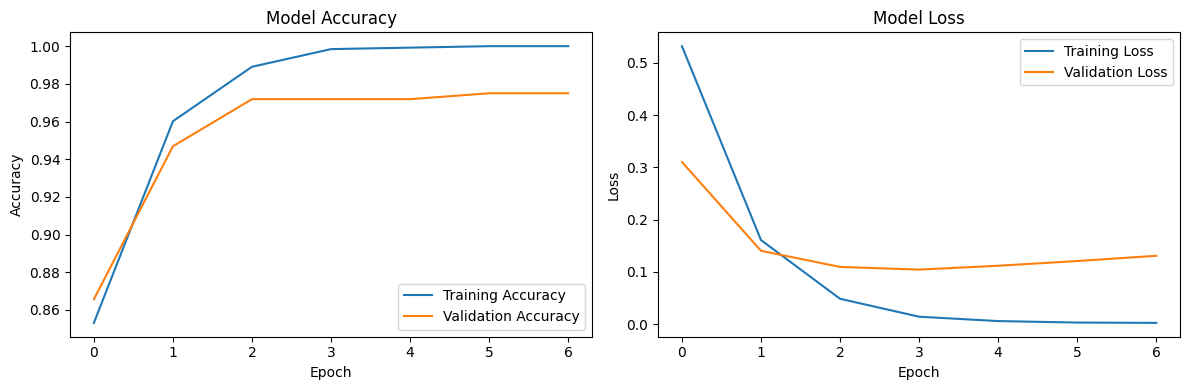

In [8]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [9]:
y_prob = model.predict(X_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("SMS SPAM DETECTION - EVALUATION")
print("-" * 35)
print(f"Accuracy  : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Ham", "Spam"],
    zero_division=0
))

SMS SPAM DETECTION - EVALUATION
-----------------------------------
Accuracy  : 0.9850 (98.50%)
Precision : 0.9583
Recall    : 0.9200
F1-score  : 0.9388

Classification Report:
              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       350
        Spam       0.96      0.92      0.94        50

    accuracy                           0.98       400
   macro avg       0.97      0.96      0.97       400
weighted avg       0.98      0.98      0.98       400



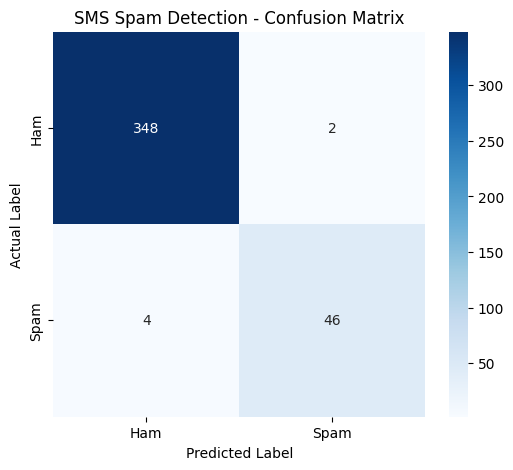

TN (Ham correctly classified): 348
FP (Ham incorrectly classified as spam): 2
FN (Spam incorrectly classified as ham): 4
TP (Spam correctly classified): 46


In [10]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("SMS Spam Detection - Confusion Matrix")
plt.show()

print("TN (Ham correctly classified):", cm[0, 0])
print("FP (Ham incorrectly classified as spam):", cm[0, 1])
print("FN (Spam incorrectly classified as ham):", cm[1, 0])
print("TP (Spam correctly classified):", cm[1, 1])

In [11]:
def predict_sms(message):
    cleaned = clean_text(message)

    sequence = tokenizer.texts_to_sequences([cleaned])
    padded = pad_sequences(
        sequence,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    probability = float(model.predict(padded, verbose=0)[0][0])
    prediction = "SPAM" if probability >= 0.5 else "HAM"

    print("Message:", message)
    print("Prediction:", prediction)
    print(f"Spam probability: {probability:.2%}")
    print("-" * 50)

# Example unseen messages
predict_sms("Congratulations! You have won a free prize. Claim now!")
predict_sms("Hi, are we meeting at college tomorrow?")
predict_sms("URGENT! You have won a cash reward. Call now!")
predict_sms("Please send me the assignment notes when you are free.")

Message: Congratulations! You have won a free prize. Claim now!
Prediction: SPAM
Spam probability: 94.70%
--------------------------------------------------
Message: Hi, are we meeting at college tomorrow?
Prediction: HAM
Spam probability: 0.02%
--------------------------------------------------
Message: URGENT! You have won a cash reward. Call now!
Prediction: SPAM
Spam probability: 67.79%
--------------------------------------------------
Message: Please send me the assignment notes when you are free.
Prediction: HAM
Spam probability: 0.18%
--------------------------------------------------


In [12]:
model.save("sms_spam_lstm.keras")

import pickle

with open("sms_tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

print("Model and tokenizer saved successfully.")

from google.colab import files
files.download("sms_spam_lstm.keras")
files.download("sms_tokenizer.pkl")

Model and tokenizer saved successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
print("Model is loaded and ready!")
model.summary()

Model is loaded and ready!


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (32, 100, 64)          │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (32, 64)               │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (32, 64)               │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (32, 32)               │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (32, 32)               │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (32, 1)                │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,065,413 (4.06 MB)

 Trainable params: 355,137 (1.35 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 710,276 (2.71 MB)

In [14]:

def check_sms():
    message = input("Enter your SMS message: ")

    # Clean the message
    cleaned_message = clean_text(message)

    # Convert text into numerical sequences
    sequence = tokenizer.texts_to_sequences([cleaned_message])

    # Pad the sequence
    padded = pad_sequences(
        sequence,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    # Get prediction from the trained model
    probability = float(model.predict(padded, verbose=0)[0][0])

    # Classify the message
    if probability >= 0.5:
        result = "SPAM"
    else:
        result = "HAM (NOT SPAM)"

    # Display output
    print("\n========== SMS SPAM DETECTOR ==========")
    print("Your message:", message)
    print("Prediction:", result)
    print(f"Spam probability: {probability:.2%}")
    print("=======================================")

# Run the detector
check_sms()


Enter your SMS message: Congratulations! You have won a free prize. Claim now!

========== SMS SPAM DETECTOR ==========
Your message: Congratulations! You have won a free prize. Claim now!
Prediction: SPAM
Spam probability: 94.70%


In [15]:

def check_sms():
    message = input("Enter your SMS message: ")

    # Clean the message
    cleaned_message = clean_text(message)

    # Convert text into numerical sequences
    sequence = tokenizer.texts_to_sequences([cleaned_message])

    # Pad the sequence
    padded = pad_sequences(
        sequence,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    # Get prediction from the trained model
    probability = float(model.predict(padded, verbose=0)[0][0])

    # Classify the message
    if probability >= 0.5:
        result = "SPAM"
    else:
        result = "HAM (NOT SPAM)"

    # Display output
    print("\n========== SMS SPAM DETECTOR ==========")
    print("Your message:", message)
    print("Prediction:", result)
    print(f"Spam probability: {probability:.2%}")
    print("=======================================")

# Run the detector
check_sms()


Enter your SMS message: Hi, are we meeting at college tomorrow?

========== SMS SPAM DETECTOR ==========
Your message: Hi, are we meeting at college tomorrow?
Prediction: HAM (NOT SPAM)
Spam probability: 0.02%



def check_sms():
    message = input("Enter your SMS message: ")

    # Clean the message
    cleaned_message = clean_text(message)

    # Convert text into numerical sequences
    sequence = tokenizer.texts_to_sequences([cleaned_message])

    # Pad the sequence
    padded = pad_sequences(
        sequence,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    # Get prediction from the trained model
    probability = float(model.predict(padded, verbose=0)[0][0])

    # Classify the message
    if probability >= 0.5:
        result = "SPAM"
    else:
        result = "HAM (NOT SPAM)"

    # Display output
    print("\n========== SMS SPAM DETECTOR ==========")
    print("Your message:", message)
    print("Prediction:", result)
    print(f"Spam probability: {probability:.2%}")
    print("=======================================")

# Run the detector
check_sms()


In [ ]:

def check_sms():
    message = input("Enter your SMS message: ")

    # Clean the message
    cleaned_message = clean_text(message)

    # Convert text into numerical sequences
    sequence = tokenizer.texts_to_sequences([cleaned_message])

    # Pad the sequence
    padded = pad_sequences(
        sequence,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    # Get prediction from the trained model
    probability = float(model.predict(padded, verbose=0)[0][0])

    # Classify the message
    if probability >= 0.5:
        result = "SPAM"
    else:
        result = "HAM (NOT SPAM)"

    # Display output
    print("\n========== SMS SPAM DETECTOR ==========")
    print("Your message:", message)
    print("Prediction:", result)
    print(f"Spam probability: {probability:.2%}")
    print("=======================================")

# Run the detector
check_sms()


Subset size: 2000
label
ham     1751
spam     249
Name: count, dtype: int64


/tmp/ipykernel_4583/2366613373.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_sample = df_sample.groupby("label", group_keys=False).apply(


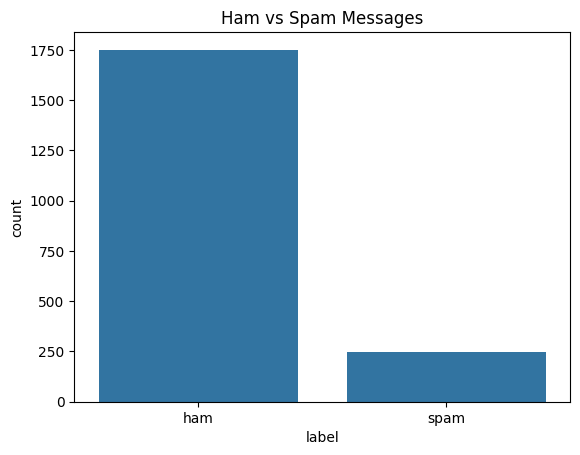

In [3]:
# Stratified sampling preserves the ham/spam ratio
df_sample = (
    df.groupby("label", group_keys=False)
      .sample(frac=1, random_state=SEED)
)

df_sample = df_sample.groupby("label", group_keys=False).apply(
    lambda group: group.sample(
        n=round(2000 * len(group) / len(df_sample)),
        random_state=SEED
    )
).reset_index(drop=True)

# Ensure exactly 2,000 rows if the dataset contains enough valid records
if len(df_sample) > 2000:
    df_sample = df_sample.sample(n=2000, random_state=SEED)

print("Subset size:", len(df_sample))
print(df_sample["label"].value_counts())

sns.countplot(data=df_sample, x="label")
plt.title("Ham vs Spam Messages")
plt.show()

In [4]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+", " URL ", text)
    text = re.sub(r"\S+@\S+", " EMAIL ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df_sample["clean_message"] = df_sample["message"].apply(clean_text)

# ham = 0, spam = 1
df_sample["target"] = df_sample["label"].map({
    "ham": 0,
    "spam": 1
})

print(df_sample[["message", "clean_message", "label", "target"]].head())

                                             message  \
0  Hey, a guy I know is breathing down my neck to...   
1  Okay lor... Will they still let us go a not ah...   
2  I will come with karnan car. Please wait till ...   
3  All boys made fun of me today. Ok i have no pr...   
4                     Thanks, I'll keep that in mind   

                                       clean_message label  target  
0  hey a guy i know is breathing down my neck to ...   ham       0  
1  okay lor will they still let us go a not ah co...   ham       0  
2  i will come with karnan car please wait till 6...   ham       0  
3  all boys made fun of me today ok i have no pro...   ham       0  
4                      thanks i ll keep that in mind   ham       0  


In [5]:
X = df_sample["clean_message"].values
y = df_sample["target"].values

# 80% training, 20% testing
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

# Fit the tokenizer on training text only
MAX_WORDS = 5000
MAX_LEN = 100

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train_text)

X_train_seq = tokenizer.texts_to_sequences(X_train_text)
X_test_seq = tokenizer.texts_to_sequences(X_test_text)

X_train = pad_sequences(
    X_train_seq, maxlen=MAX_LEN,
    padding="post", truncating="post"
)

X_test = pad_sequences(
    X_test_seq, maxlen=MAX_LEN,
    padding="post", truncating="post"
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Example token sequence:", X_train[0][:20])

Training data shape: (1600, 100)
Testing data shape: (400, 100)
Example token sequence: [   8   18   17  197    2   53  437 1183    3  173  488   16    6  127
   38  907    0    0    0    0]


In [6]:
model = Sequential([
    Embedding(
        input_dim=MAX_WORDS,
        output_dim=64,
        mask_zero=True
    ),
    LSTM(64),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [2]:
import pandas as pd
import numpy as np
import re
import random
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

df = pd.read_csv("spam_sms.csv", encoding="latin-1")

# Keep only the two required columns
df = df[["v1", "v2"]].copy()
df.columns = ["label", "message"]

# Handle missing values and duplicates
df.dropna(subset=["label", "message"], inplace=True)
df["label"] = df["label"].astype(str).str.strip().str.lower()
df["message"] = df["message"].astype(str).str.strip()

df = df[
    df["label"].isin(["ham", "spam"]) &
    (df["message"] != "")
].drop_duplicates().reset_index(drop=True)

print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df["label"].value_counts())
print("\nMissing values:")
print(df.isnull().sum())
print("\nSample messages:")
print(df.head())

Dataset shape: (5158, 2)

Class distribution:
label
ham     4516
spam     642
Name: count, dtype: int64

Missing values:
label      0
message    0
dtype: int64

Sample messages:
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
